<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/02_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — Préparation des données

Ce notebook prépare les images et les masques de segmentation du dataset RoadAnomaly pour entraîner nos modèles de Deep Learning.

## 1. Chargement des données

Nous chargeons les données depuis Google Drive et vérifions que chaque image possède son masque de segmentation correspondant.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

dataset_dir = Path(
    "/content/drive/MyDrive/deep learning P/RoadAnomaly"
)

frames_dir = dataset_dir / "RoadAnomaly" / "frames"

print("Dataset exists:", dataset_dir.exists())
print("Frames exists:", frames_dir.exists())

Dataset exists: True
Frames exists: True


## 2. Vérification des images et des masques

Nous identifions les images et leurs masques de segmentation pour vérifier que chaque image possède un masque correspondant.

In [3]:
import pandas as pd

images = sorted(frames_dir.glob("*.webp"))
pairs = []

for image_path in images:
    mask_path = (
        frames_dir
        / f"{image_path.stem}.labels"
        / "labels_semantic.png"
    )

    if mask_path.exists():
        pairs.append({
            "image": str(image_path),
            "mask": str(mask_path)
        })

df_pairs = pd.DataFrame(pairs)

print("Total images:", len(images))
print("Valid image-mask pairs:", len(df_pairs))

assert len(df_pairs) == len(images), "Missing masks detected!"

display(df_pairs.head())

Total images: 60
Valid image-mask pairs: 60


,image,mask
0,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
1,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
2,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
3,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
4,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...


## 3. Séparation des données : entraînement, validation et test

Nous divisons les 60 images en trois groupes :

- **Entraînement (70 %, 42 images) :** Pour apprendre au modèle à détecter les anomalies.
- **Validation (15 %, 9 images) :** Pour suivre les performances du modèle, éviter le surapprentissage et choisir le meilleur modèle.
- **Test (15 %, 9 images) :** Pour évaluer le modèle sur des images qu'il n'a jamais vues.

Nous utilisons une graine aléatoire fixe (42) pour obtenir la même répartition à chaque exécution.

Nous prenons aussi en compte les catégories d'anomalies pour mieux les répartir entre les trois groupes.

**Limite :** Le dataset contient seulement 60 images. Les résultats peuvent donc varier selon les images choisies pour la validation et le test.

In [4]:
from sklearn.model_selection import train_test_split
import pandas as pd

def get_category(path):
    name = str(path).split("/")[-1].lower()

    for category in ["animals", "obstacles", "cones",
                     "vehicle", "lost_tires"]:
        if name.startswith(category):
            return category

    return "other"

df_pairs["category"] = df_pairs["image"].apply(get_category)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df_pairs,
    test_size=0.30,
    random_state=42,
    stratify=df_pairs["category"]
)

# Second split: 15% validation, 15% testing
# No second stratification because some categories are small
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nCategory distribution:")
display(pd.DataFrame({
    "Train": train_df["category"].value_counts(),
    "Validation": val_df["category"].value_counts(),
    "Test": test_df["category"].value_counts()
}).fillna(0).astype(int))

Training images: 42
Validation images: 9
Testing images: 9

Category distribution:


,Train,Validation,Test
category,,,
animals,22,5,4
cones,6,0,2
lost_tires,2,0,1
obstacles,10,4,1
vehicle,2,0,1


In [5]:
train_set = set(train_df["image"])
val_set = set(val_df["image"])
test_set = set(test_df["image"])

assert not train_set & val_set
assert not train_set & test_set
assert not val_set & test_set

assert len(train_set | val_set | test_set) == 60

print("No overlap between image filenames.")
print("Split created successfully!")

No overlap between image filenames.
Split created successfully!


### 3.1. Data Leakage Verification

**Objective:** Check whether potentially related road images appear in different datasets.

We group images by their filename, ignoring trailing image numbers, and verify whether related images are assigned to different splits.

This is a preliminary check for possible data leakage.

In [6]:
import re
from pathlib import Path

def scene_group(path):
    name = Path(path).stem.lower()
    return re.sub(r"\d+$", "", name)

split_data = pd.concat([
    train_df.assign(split="Train"),
    val_df.assign(split="Validation"),
    test_df.assign(split="Test")
])

split_data["scene_group"] = split_data["image"].apply(scene_group)

potential_leakage = (
    split_data.groupby("scene_group")
    .filter(lambda g: len(g) > 1 and g["split"].nunique() > 1)
    .sort_values("scene_group")
)

print("Potentially related images across splits:",
      len(potential_leakage))

display(potential_leakage[
    ["image", "scene_group", "split"]
])

Potentially related images across splits: 7


,image,scene_group,split
40,/content/drive/MyDrive/deep learning P/RoadAno...,lost_tires,Train
41,/content/drive/MyDrive/deep learning P/RoadAno...,lost_tires,Train
39,/content/drive/MyDrive/deep learning P/RoadAno...,lost_tires,Test
54,/content/drive/MyDrive/deep learning P/RoadAno...,obstacles12_rocks,Train
55,/content/drive/MyDrive/deep learning P/RoadAno...,obstacles12_rocks,Train
53,/content/drive/MyDrive/deep learning P/RoadAno...,obstacles12_rocks,Train
56,/content/drive/MyDrive/deep learning P/RoadAno...,obstacles12_rocks,Test


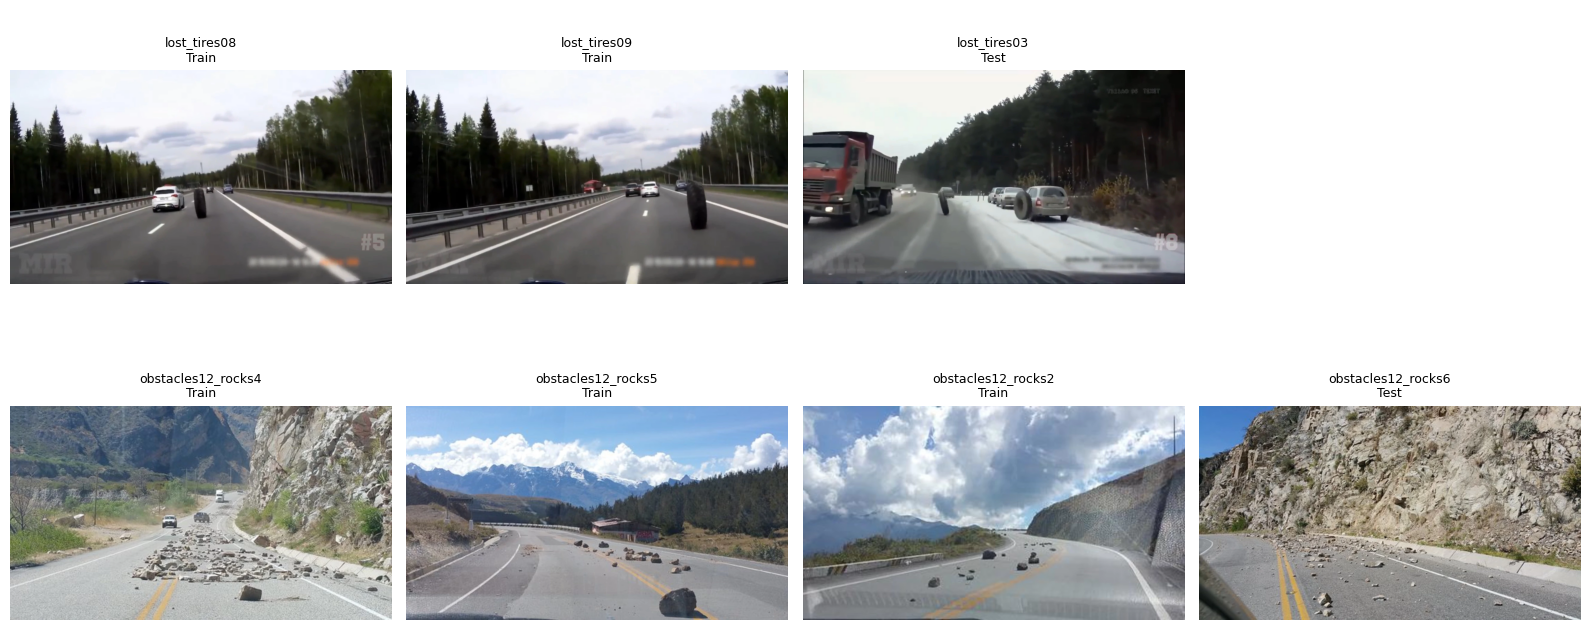

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Display potentially related images
suspected = split_data[
    split_data["scene_group"].isin(["obstacles12_rocks", "lost_tires"])
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax in axes.flat:
    ax.axis("off")

for row, (group, data) in enumerate(suspected.groupby("scene_group")):
    for col, (_, item) in enumerate(data.iterrows()):
        ax = axes[row, col]
        ax.imshow(Image.open(item["image"]).convert("RGB"))
        ax.set_title(f"{Path(item['image']).stem}\n{item['split']}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Move the related rock images into the same split

def is_rock_image(path):
    return Path(path).stem.startswith("obstacles12_rocks")

rock_test = test_df[test_df["image"].apply(is_rock_image)]

replacement = train_df[
    (train_df["category"] == "obstacles")
    & (~train_df["image"].apply(is_rock_image))
]

assert len(rock_test) == 1
assert len(replacement) > 0, "No suitable replacement found"

rock = rock_test.iloc[[0]]
other = replacement.iloc[[0]]

train_df = pd.concat([
    train_df.drop(other.index), rock
]).reset_index(drop=True)

test_df = pd.concat([
    test_df.drop(rock.index), other
]).reset_index(drop=True)

# Verify the corrected split
assert (len(train_df), len(val_df), len(test_df)) == (42, 9, 9)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Rock images in training:",
      train_df["image"].apply(is_rock_image).sum())
print("Rock images in testing:",
      test_df["image"].apply(is_rock_image).sum())

Train: 42
Validation: 9
Test: 9
Rock images in training: 4
Rock images in testing: 0


### 3.2. Vérification de la répartition finale

Nous avons vérifié les noms et les images pour éviter que des photos d'une même scène se retrouvent dans plusieurs groupes. Cela pourrait fausser les résultats du modèle.

- **Images avec des rochers :** Nous avons regroupé les images similaires dans l'ensemble d'entraînement.
- **Images avec des pneus :** Après vérification, aucun changement n'était nécessaire.

La répartition finale reste :
- **Entraînement :** 42 images
- **Validation :** 9 images
- **Test :** 9 images

Cette répartition sera sauvegardée pour utiliser les mêmes images lors de l'entraînement et de l'évaluation des différents modèles.

In [9]:
# Save the final corrected split for future experiments

final_split = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
], ignore_index=True)

split_path = Path(
    "/content/drive/MyDrive/deep learning P/split_manifest.csv"
)

final_split.to_csv(split_path, index=False)

print("Saved:", split_path)
print(final_split["split"].value_counts())

Saved: /content/drive/MyDrive/deep learning P/split_manifest.csv
split
train         42
validation     9
test           9
Name: count, dtype: int64


## 4. Prétraitement des images

Nous préparons les images et les masques de segmentation pour entraîner nos modèles de Deep Learning.

### Choix des méthodes

- **Redimensionnement (256 × 256) :** Nous réduisons la taille des images pour accélérer l'entraînement et utiliser moins de mémoire sur Google Colab. Cependant, les petites anomalies peuvent devenir plus difficiles à détecter.

- **Normalisation (0 à 1) :** Nous transformons les valeurs des pixels, initialement comprises entre 0 et 255, en valeurs entre 0 et 1 pour faciliter l'apprentissage du modèle.

- **Masques binaires (0 et 1) :** Nous utilisons deux classes :
  - **0 :** Pixels normaux (sans anomalie).
  - **1 :** Pixels anormaux (avec anomalie).

- **Interpolation :** Nous utilisons l'interpolation bilinéaire pour redimensionner les images et la méthode du plus proche voisin pour les masques, afin de conserver les bonnes valeurs des classes.

**Remarque :** Les images et les masques d'origine ne sont pas modifiés.

In [10]:
import numpy as np
from PIL import Image

IMG_SIZE = (256, 256)

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")

    # Resize image using bilinear interpolation
    image = image.resize(
        IMG_SIZE,
        Image.Resampling.BILINEAR
    )

    # Normalize pixel values to [0, 1]
    image = np.array(image, dtype=np.float32) / 255.0

    return image


def preprocess_mask(mask_path):
    mask = Image.open(mask_path)

    # Preserve class labels during resizing
    mask = mask.resize(
        IMG_SIZE,
        Image.Resampling.NEAREST
    )

    mask = np.array(mask)

    # Class 2 = anomaly, class 0 = non-anomaly
    binary_mask = (mask == 2).astype(np.uint8)

    return binary_mask


print("Preprocessing functions ready!")

Preprocessing functions ready!


### 4.1. Vérification du prétraitement

Nous appliquons le prétraitement à une image et à son masque pour vérifier :

- **Taille de l'image :** 256 × 256 × 3 (3 canaux RGB).
- **Taille du masque :** 256 × 256.
- **Valeurs des pixels :** Entre 0 et 1.
- **Valeurs du masque :** Uniquement 0 (normal) et 1 (anomalie).

Nous affichons ensuite l'image et son masque pour vérifier qu'ils correspondent toujours correctement.

Image shape: (256, 256, 3)
Mask shape: (256, 256)
Image range: 0.0 1.0
Mask unique values: [0 1]


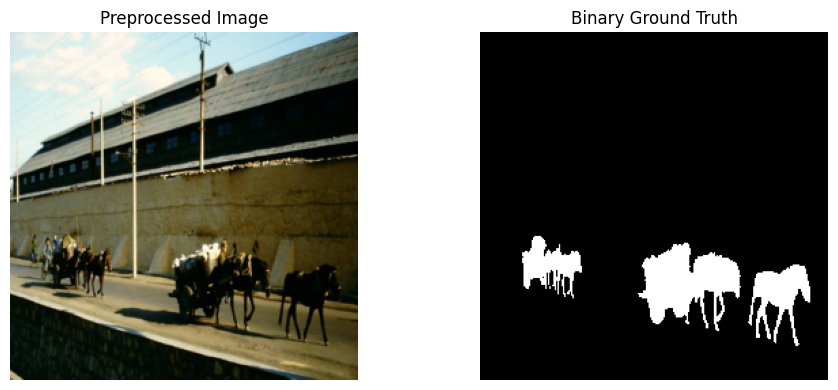

Preprocessing verification successful!


In [11]:
import matplotlib.pyplot as plt

# Select one image-mask pair
sample = train_df.iloc[0]

image = preprocess_image(sample["image"])
mask = preprocess_mask(sample["mask"])

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("Image range:", image.min(), image.max())
print("Mask unique values:", np.unique(mask))

# Verify preprocessing
assert image.shape == (256, 256, 3)
assert mask.shape == (256, 256)
assert image.min() >= 0 and image.max() <= 1
assert set(np.unique(mask)).issubset({0, 1})

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title("Preprocessed Image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Binary Ground Truth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Preprocessing verification successful!")

## 5. Augmentation des données

L'augmentation des données consiste à créer des variations aléatoires des images d'entraînement pour éviter le surapprentissage et aider le modèle à mieux reconnaître les anomalies sur de nouvelles images.

### Transformations utilisées

- **Retournement horizontal :** Inverse l'image de gauche à droite pour varier la position des obstacles.
- **Luminosité :** Rend les images plus claires ou plus sombres.
- **Contraste :** Modifie la différence entre les zones claires et sombres.

### Pourquoi utiliser l'augmentation ?

Nous avons seulement **42 images d'entraînement**. L'augmentation permet de varier les images sans avoir besoin de collecter de nouvelles données.

**Important :**
- L'augmentation est appliquée uniquement aux images d'entraînement.
- Lors du retournement horizontal, l'image et son masque sont retournés ensemble pour garder leur correspondance.
- Les images originales ne sont pas modifiées.

In [12]:
import numpy as np

rng = np.random.default_rng(42)

def augment_image_mask(image, mask, rng):
    image = image.copy()
    mask = mask.copy()

    # Random horizontal flip
    if rng.random() < 0.5:
        image = np.fliplr(image).copy()
        mask = np.fliplr(mask).copy()

    # Random brightness
    brightness = rng.uniform(0.8, 1.2)
    image = np.clip(image * brightness, 0, 1)

    # Random contrast
    contrast = rng.uniform(0.8, 1.2)
    mean = image.mean(axis=(0, 1), keepdims=True)
    image = np.clip((image - mean) * contrast + mean, 0, 1)

    return image.astype(np.float32), mask.astype(np.uint8)

print("Data augmentation ready!")

Data augmentation ready!


### 5.1. Visualisation de l'augmentation des données

Cette partie sert uniquement à visualiser les transformations appliquées aux images d'entraînement.

Nous affichons plusieurs versions d'une même image :

- **Image originale :** Sans modification.
- **Retournement horizontal :** Image inversée de gauche à droite.
- **Luminosité augmentée :** Image plus claire.
- **Luminosité diminuée :** Image plus sombre.
- **Contraste augmenté :** Différence plus marquée entre les zones claires et sombres.

**Remarque :** Pour les images de routes, le retournement horizontal est adapté. En revanche, le retournement vertical et les grandes rotations ne sont pas utilisés, car ils produisent des scènes peu réalistes.

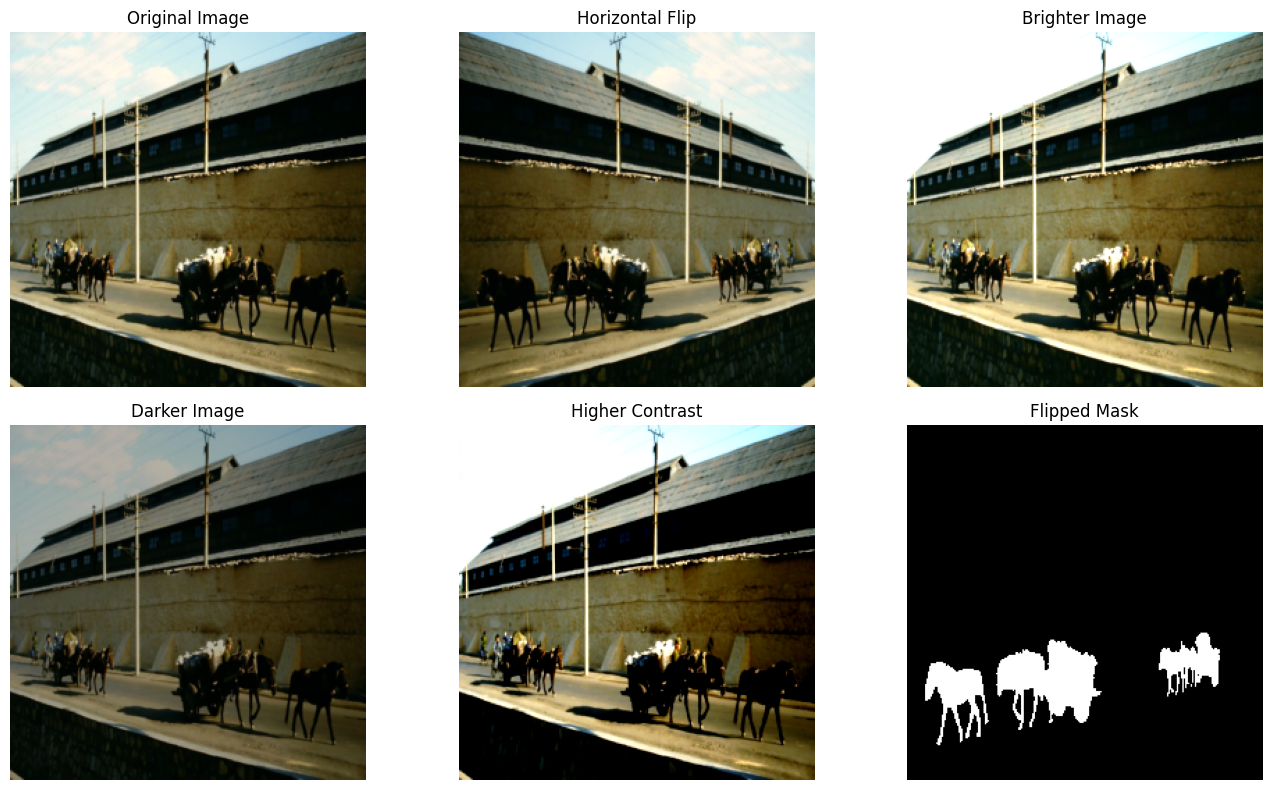

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Select one training example
sample = train_df.iloc[0]

image = preprocess_image(sample["image"])
mask = preprocess_mask(sample["mask"])

# Variants for visualization only
original = image.copy()
flipped = np.fliplr(image).copy()
flipped_mask = np.fliplr(mask).copy()

brighter = np.clip(image * 1.3, 0, 1)
darker = np.clip(image * 0.7, 0, 1)

mean = image.mean(axis=(0, 1), keepdims=True)
higher_contrast = np.clip((image - mean) * 1.4 + mean, 0, 1)

# Show image variants
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(original)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(flipped)
axes[0, 1].set_title("Horizontal Flip")

axes[0, 2].imshow(brighter)
axes[0, 2].set_title("Brighter Image")

axes[1, 0].imshow(darker)
axes[1, 0].set_title("Darker Image")

axes[1, 1].imshow(higher_contrast)
axes[1, 1].set_title("Higher Contrast")

axes[1, 2].imshow(flipped_mask, cmap="gray", vmin=0, vmax=1)
axes[1, 2].set_title("Flipped Mask")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Dataset et DataLoader avec PyTorch

Le **Dataset** de PyTorch permet de charger chaque image avec son masque de segmentation. Il applique le prétraitement et, si nécessaire, l'augmentation des données.

Le **DataLoader** regroupe les images et leurs masques en petits lots (*batches*) pour entraîner le modèle U-Net.

### Choix utilisés

- **Entraînement :** Augmentation aléatoire des images et mélange de leur ordre.
- **Validation et test :** Sans augmentation ni mélange, pour évaluer le modèle sur les images originales prétraitées.
- **Taille du batch :** 4 images à la fois, pour utiliser moins de mémoire.
- **Format des images :** `(3, 256, 256)` → 3 canaux RGB et une taille de 256 × 256.
- **Format des masques :** `(1, 256, 256)` → 1 canal contenant les valeurs 0 (normal) et 1 (anomalie).

**Objectif :** Préparer les images et leurs masques dans le bon format pour entraîner U-Net à détecter les anomalies sur les routes.

In [14]:
import torch
from torch.utils.data import Dataset, DataLoader

class RoadAnomalyDataset(Dataset):
    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = preprocess_image(row["image"])
        mask = preprocess_mask(row["mask"])

        if self.augment:
            image, mask = augment_image_mask(
                image, mask, self.rng
            )

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        mask = torch.from_numpy(
            np.ascontiguousarray(mask[None, :, :])
        ).float()

        return image, mask


# Create datasets
train_dataset = RoadAnomalyDataset(train_df, augment=True)
val_dataset = RoadAnomalyDataset(val_df, augment=False)
test_dataset = RoadAnomalyDataset(test_df, augment=False)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=4, shuffle=False, num_workers=0
)

# Verify one batch
images_batch, masks_batch = next(iter(train_loader))

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

print("Image batch shape:", images_batch.shape)
print("Mask batch shape:", masks_batch.shape)

assert images_batch.shape == (4, 3, 256, 256)
assert masks_batch.shape == (4, 1, 256, 256)
assert set(torch.unique(masks_batch).tolist()).issubset({0.0, 1.0})

print("DataLoaders ready for U-Net!")

Training samples: 42
Validation samples: 9
Testing samples: 9
Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 1, 256, 256])
DataLoaders ready for U-Net!


In [15]:
# Final verification of all three datasets

for name, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    total = 0

    for imgs, masks in loader:
        assert imgs.ndim == 4 and imgs.shape[1:] == (3, 256, 256)
        assert masks.ndim == 4 and masks.shape[1:] == (1, 256, 256)
        assert torch.isfinite(imgs).all()
        assert torch.isfinite(masks).all()
        assert imgs.min() >= 0 and imgs.max() <= 1
        assert torch.all((masks == 0) | (masks == 1))
        total += len(imgs)

    assert total == len(loader.dataset)
    print(f"{name}: {total} samples verified")

# Check that no image appears in multiple splits
train_paths = set(train_df["image"])
val_paths = set(val_df["image"])
test_paths = set(test_df["image"])

assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)

print("No duplicate image paths across splits.")
print("Data Preparation verification passed!")

Train: 42 samples verified
Validation: 9 samples verified
Test: 9 samples verified
No duplicate image paths across splits.
Data Preparation verification passed!
